In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [2]:
SEED = 42
LEARNING_RATE = 0.5
EPOCHS = 10000
OUTPUT_DIR = Path('outputs/exp01')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
targets = {
    'AND': np.array([[0], [0], [0], [1]], dtype=float),
    'OR': np.array([[0], [1], [1], [1]], dtype=float),
    'NAND': np.array([[1], [1], [1], [0]], dtype=float),
    'XOR': np.array([[0], [1], [1], [0]], dtype=float),
}


In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


In [4]:
def train_network(
    X,
    y,
    hidden_units=0,
    epochs=EPOCHS,
    patience=200,
    min_delta=1e-6,
    target_loss=0.01,
):
    rng = np.random.default_rng(SEED)
    sizes = [X.shape[1], hidden_units, 1] if hidden_units else [X.shape[1], 1]
    weights = [rng.uniform(-1, 1, (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]
    biases = [rng.uniform(-1, 1, (1, b)) for b in sizes[1:]]
    losses = []
    best_loss = np.inf
    best_weights = [W.copy() for W in weights]
    best_biases = [b.copy() for b in biases]
    wait = 0

    for epoch in range(epochs):
        activations = [X]
        for W, b in zip(weights, biases):
            activations.append(sigmoid(activations[-1] @ W + b))

        output = activations[-1]
        delta = (output - y) / len(X)
        gradients = []
        for i in range(len(weights) - 1, -1, -1):
            gradients.append(
                (i, activations[i].T @ delta, delta.sum(axis=0, keepdims=True)),
            )
            if i:
                delta = delta @ weights[i].T * activations[i] * (1 - activations[i])
        for i, dW, db in gradients:
            weights[i] -= LEARNING_RATE * dW
            biases[i] -= LEARNING_RATE * db

        output = predict(X, weights, biases)
        positive_loss = y * np.log(output + 1e-12)
        negative_loss = (1 - y) * np.log(1 - output + 1e-12)
        loss = float(-np.mean(positive_loss + negative_loss))
        losses.append(loss)

        if loss < best_loss - min_delta:
            best_loss = loss
            best_weights = [W.copy() for W in weights]
            best_biases = [b.copy() for b in biases]
            wait = 0
        else:
            wait += 1

        if loss <= target_loss or wait >= patience:
            print(f'Early stopping at epoch {epoch + 1}: loss={loss:.5f}')
            break

    return best_weights, best_biases, losses


In [5]:
def predict(X, weights, biases):
    output = X
    for W, b in zip(weights, biases):
        output = sigmoid(output @ W + b)
    return output


Early stopping at epoch 3478: loss=0.01000
AND: 100% accuracy


,x1,x2,Expected,Probability,Prediction
0,0,0,0,0.0000,0
1,0,1,0,0.0117,0
2,1,0,0,0.0117,0
3,1,1,1,0.9836,1


Early stopping at epoch 1865: loss=0.01000
OR: 100% accuracy


,x1,x2,Expected,Probability,Prediction
0,0,0,0,0.0221,0
1,0,1,1,0.9912,1
2,1,0,1,0.9912,1
3,1,1,1,1.0000,1


Early stopping at epoch 3472: loss=0.01000
NAND: 100% accuracy


,x1,x2,Expected,Probability,Prediction
0,0,0,1,1.0000,1
1,0,1,1,0.9883,1
2,1,0,1,0.9883,1
3,1,1,0,0.0164,0


Early stopping at epoch 3047: loss=0.01000
XOR: 100% accuracy


,x1,x2,Expected,Probability,Prediction
0,0,0,0,0.0012,0
1,0,1,1,0.9891,1
2,1,0,1,0.9891,1
3,1,1,0,0.0168,0


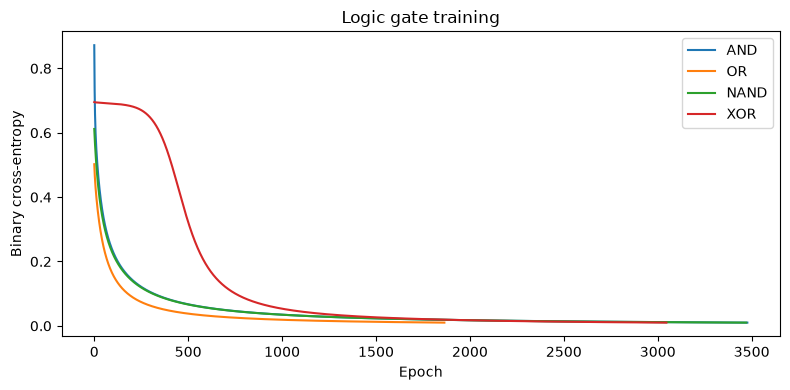

,Gate,Accuracy,Final loss
0,AND,1.0,0.01
1,OR,1.0,0.01
2,NAND,1.0,0.01
3,XOR,1.0,0.01


In [6]:
results = []
trained = {}
fig, ax = plt.subplots(figsize=(8, 4))
for gate, y in targets.items():
    weights, biases, losses = train_network(
        X,
        y,
        hidden_units=4 if gate == 'XOR' else 0,
    )
    probabilities = predict(X, weights, biases)
    predictions = (probabilities >= 0.5).astype(int)
    assert np.array_equal(predictions, y.astype(int)), f'Incorrect {gate} predictions'
    assert losses[-1] < losses[0], f'{gate} loss did not decrease'
    table = pd.DataFrame(
        {
            'x1': X[:, 0].astype(int),
            'x2': X[:, 1].astype(int),
            'Expected': y.ravel().astype(int),
            'Probability': probabilities.ravel(),
            'Prediction': predictions.ravel(),
        },
    )
    print(f'{gate}: {np.mean(predictions == y):.0%} accuracy')
    display(table.round(4))
    table.to_csv(OUTPUT_DIR / f'{gate.lower()}_truth_table.csv', index=False)
    trained[gate] = (weights, biases)
    arrays = {f'W{i}': W for i, W in enumerate(weights)}
    arrays.update({f'b{i}': b for i, b in enumerate(biases)})
    np.savez(OUTPUT_DIR / f'{gate.lower()}_weights.npz', **arrays)
    ax.plot(losses, label=gate)
    results.append(
        {
            'Gate': gate,
            'Accuracy': np.mean(predictions == y),
            'Final loss': losses[-1],
        },
    )

ax.set(xlabel='Epoch', ylabel='Binary cross-entropy', title='Logic gate training')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_loss.png', dpi=150)
plt.show()
display(pd.DataFrame(results).round(5))
